# 02 · Day-ahead forecasting

**Task:** on gas day *D* at 12:00, forecast total demand for gas day *D+1*.

**Information used** (all public at 12:00 on day *D*):
- Snam's intraday estimate of today's demand
- forecast heating degree-days for tomorrow
- settled demand of previous weeks
- calendar (day of week, holidays, bridges, August/Christmas breaks)

**Benchmark:** Snam's own day-ahead forecast published at the same hour. Snam also uses shippers' nominations, which are not public, so it is a demanding reference.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

import data, model, plots
plots.set_style()
gwh = FuncFormatter(lambda x, _: f"{x/1e3:,.0f}")

In [2]:
daily = pd.read_csv(data.PROCESSED_FILE, index_col="date", parse_dates=True)
df = model.add_features(daily)
df[model.FEATURES + ["target_delta"]].dropna().head()

,demand_today_at_issue,hdd_forecast,delta_hdd,delta_lag_7,dow_sin,dow_cos,is_off,prev_is_off,off_transition,is_bridge,is_august_break,target_delta
date,,,,,,,,,,,,
2023-01-08,1842991.003,10.08,0.00,-174303.925,-0.781831,0.623490,1,1.0,0.0,0,0,-39912.339
2023-01-09,1794378.263,9.28,0.00,439496.253,0.000000,1.000000,0,1.0,-1.0,0,0,753349.107
2023-01-10,2246737.300,8.64,0.00,-12619.370,0.781831,0.623490,0,0.0,0.0,0,0,172960.858
2023-01-11,2465879.061,11.30,0.92,-111565.445,0.974928,-0.222521,0,0.0,0.0,0,0,199436.771
2023-01-12,2687871.455,10.70,-0.38,106792.028,0.433884,-0.900969,0,0.0,0.0,0,0,26713.455


## Walk-forward backtest
Test period: **1 July – 30 December 2023** (183 days). The models are re-trained every 7 days on all data available up to that point (expanding window), so no information from the future is ever used.

In [3]:
results = model.walk_forward(df, test_start="2023-07-01", refit_every=7)
scores = model.score(results)
scores.round(3)

,MAE (GWh/day),MAPE (%),R²
model,,,
Snam forecast,72.447,4.475,0.969
Random Forest,93.102,6.145,0.955
Gradient Boosting,93.393,6.402,0.954
Linear Regression,118.063,7.424,0.924
Naive (today's estimate),196.993,12.648,0.751
Seasonal naive (t-7),212.140,13.320,0.736


In [4]:
best = "Gradient Boosting"
base = scores.loc["Seasonal naive (t-7)", "MAE (GWh/day)"]
print(f"{best}: MAE {scores.loc[best, 'MAE (GWh/day)']:.0f} GWh/day, "
      f"{1 - scores.loc[best, 'MAE (GWh/day)'] / base:.0%} lower than the seasonal naive baseline")

Gradient Boosting: MAE 93 GWh/day, 56% lower than the seasonal naive baseline


## Results by month
During the heating season (October–December) the model is **on par with Snam's forecast**. It struggles in August: the summer shutdown appears only once in a single year of data, so it cannot be learned from history.

In [5]:
monthly = []
for month, g in results.groupby(results.index.month):
    s = model.score(g)
    monthly.append({
        "month": pd.Timestamp(2023, month, 1).strftime("%b"),
        "Gradient Boosting MAPE (%)": s.loc["Gradient Boosting", "MAPE (%)"],
        "Snam MAPE (%)": s.loc["Snam forecast", "MAPE (%)"],
        "Seasonal naive MAPE (%)": s.loc["Seasonal naive (t-7)", "MAPE (%)"],
    })
monthly = pd.DataFrame(monthly).set_index("month").round(1)
monthly

,Gradient Boosting MAPE (%),Snam MAPE (%),Seasonal naive MAPE (%)
month,,,
Jul,6.3,4.0,10.5
Aug,13.3,6.1,21.7
Sep,5.3,4.0,10.2
Oct,3.7,3.6,7.1
Nov,4.0,3.7,15.5
Dec,5.7,5.5,15.0


In [6]:
q4 = model.score(results.loc["2023-10-01":])
q4.round(3)

,MAE (GWh/day),MAPE (%),R²
model,,,
Snam forecast,84.715,4.238,0.959
Gradient Boosting,85.474,4.454,0.960
Random Forest,93.593,4.763,0.956
Linear Regression,134.858,7.135,0.906
Naive (today's estimate),220.761,11.772,0.712
Seasonal naive (t-7),243.906,12.468,0.664


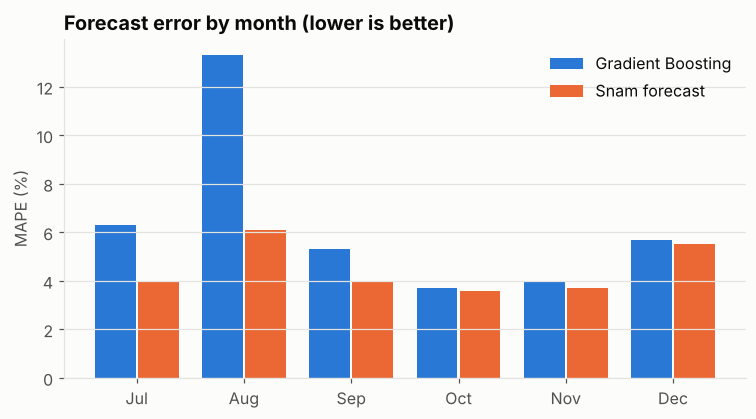

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(monthly))
w = 0.38
ax.bar(x - w/2 - 0.01, monthly["Gradient Boosting MAPE (%)"], w, color=plots.MODEL, label="Gradient Boosting")
ax.bar(x + w/2 + 0.01, monthly["Snam MAPE (%)"], w, color=plots.SNAM, label="Snam forecast")
ax.set_xticks(x, monthly.index)
ax.set_ylabel("MAPE (%)")
ax.set_title("Forecast error by month (lower is better)")
ax.legend()
plots.save(fig, "error_by_month.png")

## Forecast vs actual – heating season

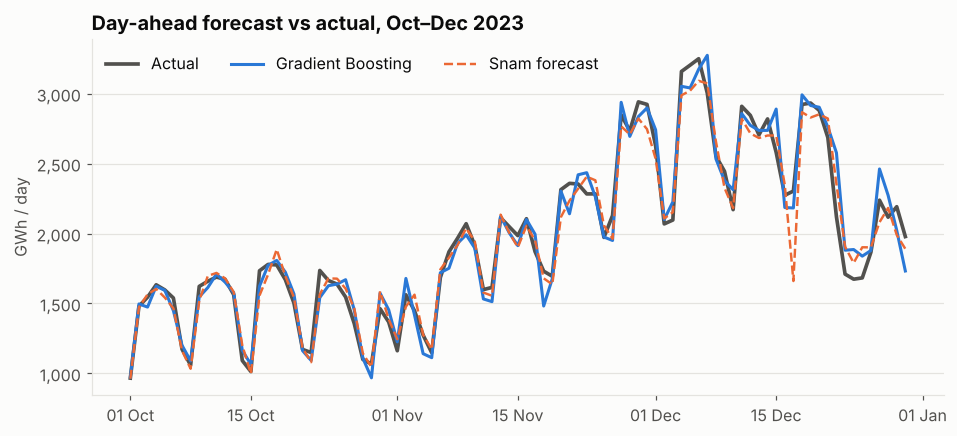

In [8]:
r = results.loc["2023-10-01":]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(r.index, r["actual"], color=plots.ACTUAL, linewidth=2.4, label="Actual")
ax.plot(r.index, r["Gradient Boosting"], color=plots.MODEL, label="Gradient Boosting")
ax.plot(r.index, r["Snam forecast"], color=plots.SNAM, linewidth=1.6, linestyle="--", label="Snam forecast")
ax.yaxis.set_major_formatter(gwh)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_ylabel("GWh / day")
ax.set_title("Day-ahead forecast vs actual, Oct–Dec 2023")
ax.legend(loc="upper left", ncol=3)
plots.save(fig, "forecast_vs_actual.png")

## What drives the forecast
Permutation importance on the last 90 days of the series (model trained on all data before them).

off_transition           182.2
demand_today_at_issue     21.8
delta_hdd                 18.7
dow_sin                   16.8
hdd_forecast               9.4
delta_lag_7                2.9
dow_cos                    2.1
prev_is_off                0.0
is_august_break            0.0
is_bridge                  0.0
is_off                    -0.0
dtype: float64

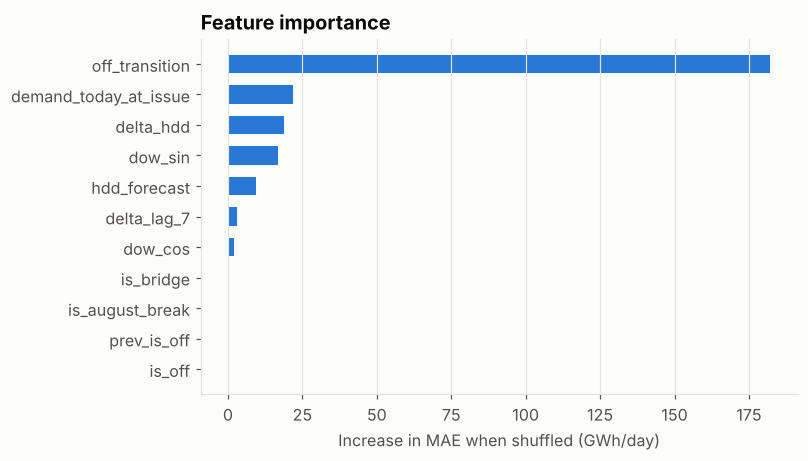

In [9]:
from sklearn.inspection import permutation_importance

data_ = df.dropna(subset=model.FEATURES + ["target_delta"])
train, test = data_.iloc[:-90], data_.iloc[-90:]
gb = model.MODELS["Gradient Boosting"]().fit(train[model.FEATURES], train["target_delta"])
imp = permutation_importance(gb, test[model.FEATURES], test["target_delta"],
                             n_repeats=30, random_state=42, scoring="neg_mean_absolute_error")
importance = pd.Series(imp.importances_mean / 1e3, index=model.FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(importance.index, importance.values, color=plots.MODEL, height=0.6)
ax.set_xlabel("Increase in MAE when shuffled (GWh/day)")
ax.set_title("Feature importance")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plots.save(fig, "feature_importance.png")
importance.sort_values(ascending=False).round(1)

## Conclusions
- Modelling the **day-to-day change** instead of the level is the key design choice: tree models cannot extrapolate the seasonal level, but they learn the change well.
- Over Oct–Dec the Gradient Boosting model matches Snam's operational forecast using **public data only**.
- Main limitation: one year of history. Rare events (August shutdown, Christmas) are seen once at most. Adding the 2017–2022 reports from Snam's website is the obvious next step.